In [ ]:
import pandas as pd

In [ ]:
ch=pd.read_csv('employee_attrition_dataset_10000.csv')
ch.head()

,Employee_ID,Age,Gender,Marital_Status,Department,Job_Role,Job_Level,Monthly_Income,Hourly_Rate,Years_at_Company,...,Overtime,Project_Count,Average_Hours_Worked_Per_Week,Absenteeism,Work_Environment_Satisfaction,Relationship_with_Manager,Job_Involvement,Distance_From_Home,Number_of_Companies_Worked,Attrition
0,1,58,Male,Single,Finance,Manager,5,7332,81,24,...,No,9,48,16,4,1,1,49,3,No
1,2,48,Female,Divorced,HR,Assistant,4,6069,55,18,...,Yes,9,57,10,4,1,1,25,1,No
2,3,34,Female,Married,Marketing,Manager,4,11485,65,6,...,Yes,3,55,1,1,4,3,21,1,Yes
3,4,27,Female,Divorced,HR,Manager,4,18707,28,12,...,No,9,53,2,3,4,1,46,2,No
4,5,40,Male,Married,HR,Analyst,1,16398,92,3,...,No,1,54,11,1,1,1,43,4,No


In [ ]:
missing_data=ch.isnull().sum().sum()
print("total missing cells found:",missing_data)

total missing cells found: 0


In [ ]:
ch['Attrition']=ch['Attrition'].map({'Yes':1,'NO':2})

# Phase: 1 and 2

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Load your custom 10,000-row HR dataset
df = pd.read_csv('employee_attrition_dataset_10000.csv')
print(f"Custom Data Loaded Successfully: {df.shape[0]} Employees, {df.shape[1]} Features.")

Custom Data Loaded Successfully: 10000 Employees, 26 Features.


# Phase 3 - Data Preprocessing

In [ ]:
print("Starting Preprocessing...")

# 1. Target Encoding: Map 'Yes'/'No' to 1/0
df['Attrition'] = df['Attrition'].map({'Yes': 1, 'No': 0})

# 2. Label Encoding: For columns with only 2 categories (Male/Female, Yes/No)
binary_cols = ['Gender', 'Overtime']
le = LabelEncoder()
for col in binary_cols:
    df[col] = le.fit_transform(df[col])

# 3. One-Hot Encoding: For columns with 3+ categories
multi_cols = ['Marital_Status', 'Department', 'Job_Role']
df = pd.get_dummies(df, columns=multi_cols, drop_first=True)

print(f"Preprocessing Complete. New Feature Count: {df.shape[1]}")

Starting Preprocessing...
Preprocessing Complete. New Feature Count: 32


# Phase 4 - Exploratory Data Analysis (EDA)

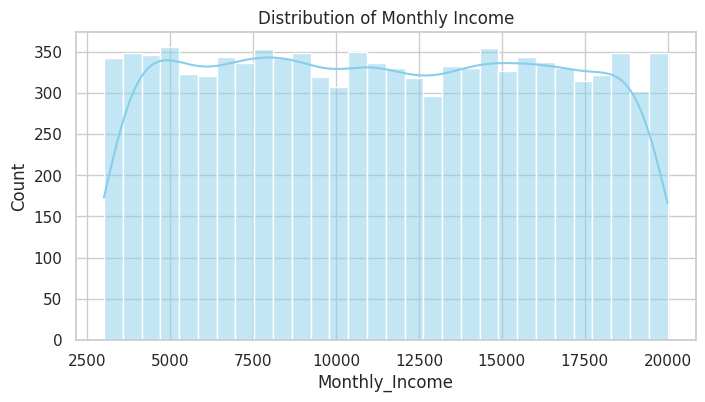

/tmp/ipykernel_28380/4031164238.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Attrition', y='Average_Hours_Worked_Per_Week', data=df, palette='Set2')


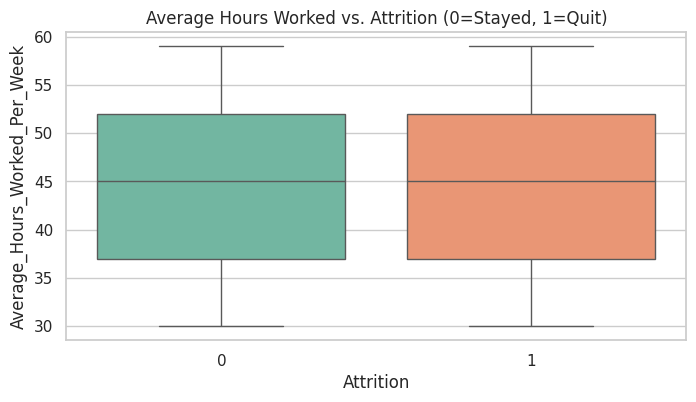

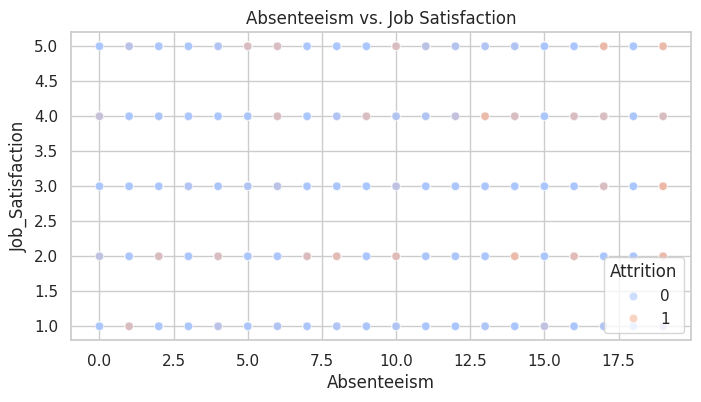

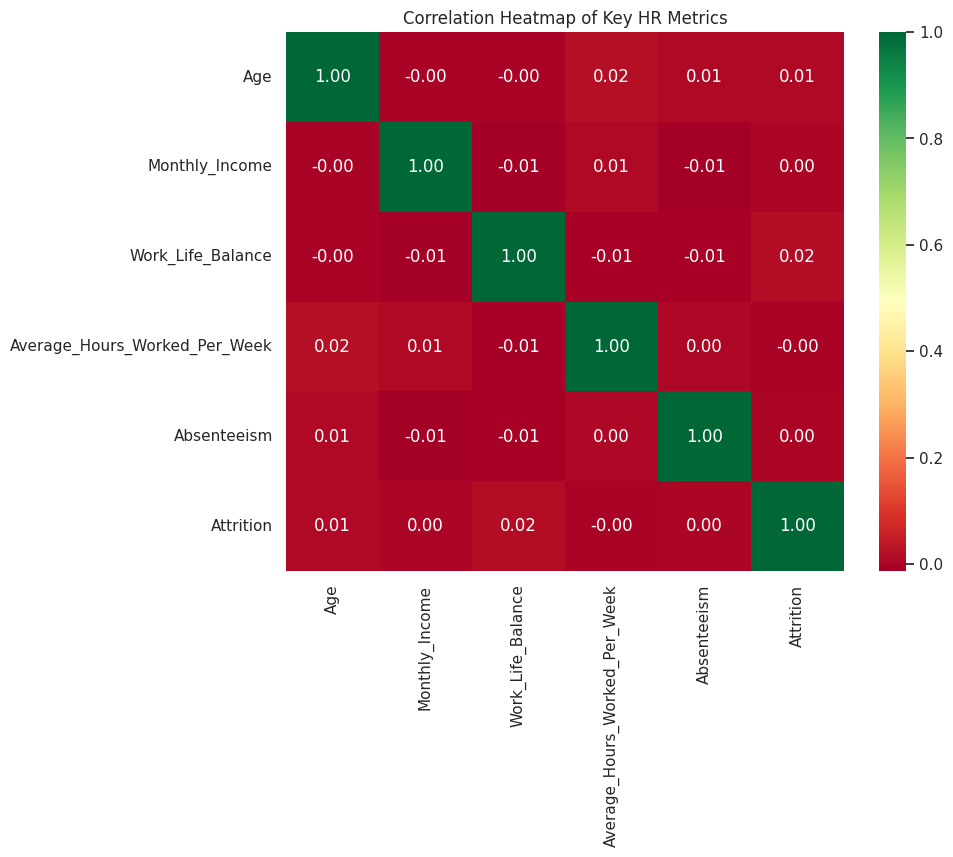

In [ ]:
sns.set_theme(style="whitegrid")

sns.set_theme(style="whitegrid")

# 1. Univariate: Histogram of Monthly Income
plt.figure(figsize=(8, 4))
sns.histplot(df['Monthly_Income'], bins=30, kde=True, color='skyblue')
plt.title('Distribution of Monthly Income')
plt.show()

# 2. Bivariate: Boxplot of Average Hours Worked vs Attrition
plt.figure(figsize=(8, 4))
sns.boxplot(x='Attrition', y='Average_Hours_Worked_Per_Week', data=df, palette='Set2')
plt.title('Average Hours Worked vs. Attrition (0=Stayed, 1=Quit)')
plt.show()

# 3. Bivariate: Scatter Plot of Absenteeism vs Job Satisfaction
plt.figure(figsize=(8, 4))
sns.scatterplot(x='Absenteeism', y='Job_Satisfaction', hue='Attrition', data=df, alpha=0.6, palette='coolwarm')
plt.title('Absenteeism vs. Job Satisfaction')
plt.show()

# 4. Correlation: Heatmap of Key Metrics from your dataset
plt.figure(figsize=(9, 7))
key_metrics = df[['Age', 'Monthly_Income', 'Work_Life_Balance', 'Average_Hours_Worked_Per_Week', 'Absenteeism', 'Attrition']]
sns.heatmap(key_metrics.corr(), annot=True, cmap='RdYlGn', fmt=".2f")
plt.title('Correlation Heatmap of Key HR Metrics')
plt.show()

# Phase 5 - Feature Engineering

In [ ]:
# Drop columns that provide no predictive value
df = df.drop(['Employee_ID'], axis=1)

# Separate the Target (Answers) from the Features (Questions)
y = df['Attrition']
X = df.drop('Attrition', axis=1)

# Split: 80% Training, 20% Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Training Data: {X_train.shape[0]} rows.")
print(f"Testing Data: {X_test.shape[0]} rows.")

Training Data: 8000 rows.
Testing Data: 2000 rows.


# Phase 6 & 7 - Model Building & Evaluation

In [ ]:
   # Initialize the three required models
models = {
    "Logistic Regression": LogisticRegression(max_iter=10000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
}

best_model = None
highest_f1 = 0

print("--- EVALUATION RESULTS ---")
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds)

    print(f"{name}:")
    print(f"  Accuracy: {acc*100:.2f}% | F1 Score: {f1*100:.2f}%")

    # Save the model with the highest F1 Score
    if f1 > highest_f1:
        highest_f1 = f1
        best_model = model

# Export the winning model and column structure for the web app
with open('hr_model.pkl', 'wb') as file:
    pickle.dump(best_model, file)
with open('model_columns.pkl', 'wb') as file:
    pickle.dump(list(X_train.columns), file)

print("\nModel saved successfully as 'hr_model.pkl'!")

--- EVALUATION RESULTS ---


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression:
  Accuracy: 79.60% | F1 Score: 0.00%
Random Forest:
  Accuracy: 79.60% | F1 Score: 0.00%


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [17:54:06] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost:
  Accuracy: 77.85% | F1 Score: 3.06%

Model saved successfully as 'hr_model.pkl'!
